In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


# Exploring Rule Learning and Generalization in Small Language Models

## 1. Project Overview

This project examines whether a compact instruction-tuned language model can learn symbolic transformation rules through parameter-efficient fine-tuning and apply them to an unseen transformation.

The experiment focuses on:

1. Learning simple symbolic transformations from examples.
2. Evaluating performance on a transformation parameter not used during training.
3. Comparing model behaviour under two instruction formats.

The task uses a cyclic sequence of symbols (A–H), where each input is shifted forward by a specified number of positions. The study compares training performance with validation performance to examine whether the model's behaviour indicates memorisation or generalization.


In [ ]:
import torch
import transformers
import peft
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
PEFT: 0.21.2
Accelerate: 1.15.0
CUDA available: True
GPU: Tesla T4


## 2. Model Selection

The Qwen2.5-0.5B-Instruct model is used as the base model for this experiment. It is a compact, open-weight instruction-tuned language model suitable for a small-scale fine-tuning study.

LoRA is applied to selected attention projection layers so that the experiment can adapt a limited number of parameters rather than fine-tuning the entire model.

The model is evaluated on the symbolic transformation task before and after fine-tuning. The main focus is its performance on a transformation parameter excluded from the training examples.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Model loaded successfully!")
print("Model:", model_name)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully!
Model: Qwen/Qwen2.5-0.5B-Instruct


## 3. Dataset Design

A synthetic dataset is generated for a cyclic symbol-transformation task.

The dataset is divided into:
- **Training set:** examples using shifts of +1 and +2.
- **Validation set:** examples using the unseen shift of +3.

Each example contains an instruction, an input symbol, and the expected output symbol. The transformation wraps around the sequence after H, returning to A.

Training and validation examples are generated separately. Performance is measured using exact-match accuracy, with the validation set used to assess performance on the unseen shift.


In [ ]:
import random

SYMBOLS = ["A", "B", "C", "D", "E", "F", "G", "H"]

def transform_symbol(symbol, shift):
    index = SYMBOLS.index(symbol)
    return SYMBOLS[(index + shift) % len(SYMBOLS)]

# Example rules
for symbol in ["A", "B", "C", "D"]:
    print(
        f"Input: {symbol}, "
        f"Rule: Shift by 2, "
        f"Output: {transform_symbol(symbol, 2)}"
    )

Input: A, Rule: Shift by 2, Output: C
Input: B, Rule: Shift by 2, Output: D
Input: C, Rule: Shift by 2, Output: E
Input: D, Rule: Shift by 2, Output: F


In [ ]:
def generate_examples(shifts, symbols=SYMBOLS):
    examples = []

    for shift in shifts:
        for symbol in symbols:
            output = transform_symbol(symbol, shift)

            examples.append({
                "instruction": f"Apply the rule: shift the symbol forward by {shift} positions.",
                "input": symbol,
                "output": output
            })

    return examples


dataset = generate_examples([1, 2, 3])

print("Total examples:", len(dataset))
print("\nFirst 5 examples:")

for example in dataset[:5]:
    print(example)

Total examples: 24

First 5 examples:
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'A', 'output': 'B'}
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'B', 'output': 'C'}
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'C', 'output': 'D'}
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'D', 'output': 'E'}
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'E', 'output': 'F'}


In [ ]:
train_dataset = generate_examples([1, 2])
val_dataset = generate_examples([3])

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print(example)

Training examples: 16
Validation examples: 8
{'instruction': 'Apply the rule: shift the symbol forward by 1 positions.', 'input': 'E', 'output': 'F'}


In [ ]:
def format_examples(examples):
    formatted = []

    for item in examples:
        text = (
            f"{item['instruction']}\n"
            f"Input: {item['input']}\n"
            f"Output: {item['output']}"
        )

        formatted.append(text)

    return formatted


train_texts = format_examples(train_dataset)
val_texts = format_examples(val_dataset)

print("Training sample:")
print(train_texts[0])

print("\nValidation sample:")
print(val_texts[0])

Training sample:
Apply the rule: shift the symbol forward by 1 positions.
Input: A
Output: B

Validation sample:
Apply the rule: shift the symbol forward by 3 positions.
Input: A
Output: D


In [ ]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print(
    "Trainable percentage:",
    round(trainable_params / total_params * 100, 2), "%"
)

Total parameters: 494032768
Trainable parameters: 494032768
Trainable percentage: 100.0 %


In [ ]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    bias="none"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


In [ ]:
def prepare_sft_data(examples):

    full_texts = []
    prompt_lengths = []

    for item in examples:
        prompt = (
            f"{item['instruction']}\n"
            f"Input: {item['input']}\n"
            "Output:"
        )

        full_text = (
            prompt + " " + item["output"] + tokenizer.eos_token
        )

        full_texts.append(full_text)

        prompt_tokens = tokenizer(
            prompt,
            add_special_tokens=True
        )

        prompt_lengths.append(len(prompt_tokens["input_ids"]))

    tokens = tokenizer(
        full_texts,
        padding=True,
        truncation=True,
        max_length=64,
        return_tensors="pt"
    )

    labels = tokens["input_ids"].clone()

    for i, prompt_length in enumerate(prompt_lengths):
        labels[i, :prompt_length] = -100

    labels[tokens["attention_mask"] == 0] = -100

    tokens["labels"] = labels

    return tokens


train_tokens = prepare_sft_data(train_dataset)
val_tokens = prepare_sft_data(val_dataset)

print("Training shape:", train_tokens["input_ids"].shape)
print("Validation shape:", val_tokens["input_ids"].shape)

print("\nTraining labels:")
print(train_tokens["labels"][0])

Training shape: torch.Size([16, 21])
Validation shape: torch.Size([8, 21])

Training labels:
tensor([  -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,
          -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,   -100,
          -100,    425, 151645])


In [ ]:
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

for i in range(5):
    print(f"\nExample {i+1}")
    print("Instruction:", train_dataset[i]["instruction"])
    print("Input:", train_dataset[i]["input"])
    print("Expected output:", train_dataset[i]["output"])

Training examples: 16
Validation examples: 8

Example 1
Instruction: Apply the rule: shift the symbol forward by 1 positions.
Input: A
Expected output: B

Example 2
Instruction: Apply the rule: shift the symbol forward by 1 positions.
Input: B
Expected output: C

Example 3
Instruction: Apply the rule: shift the symbol forward by 1 positions.
Input: C
Expected output: D

Example 4
Instruction: Apply the rule: shift the symbol forward by 1 positions.
Input: D
Expected output: E

Example 5
Instruction: Apply the rule: shift the symbol forward by 1 positions.
Input: E
Expected output: F


In [ ]:
train_inputs = {item["input"] for item in train_dataset}
val_inputs = {item["input"] for item in val_dataset}

print("Training inputs:", sorted(train_inputs))
print("Validation inputs:", sorted(val_inputs))

print("\nOverlapping inputs:", train_inputs.intersection(val_inputs))
print("No overlap:", len(train_inputs.intersection(val_inputs)) == 0)

Training inputs: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Validation inputs: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

Overlapping inputs: {'A', 'E', 'C', 'F', 'G', 'D', 'H', 'B'}
No overlap: False


In [ ]:
train_examples = {
    (x["instruction"], x["input"], x["output"])
    for x in train_dataset
}

val_examples = {
    (x["instruction"], x["input"], x["output"])
    for x in val_dataset
}

print("Exact duplicate examples:", train_examples & val_examples)
print("Unique training examples:", len(train_examples))
print("Unique validation examples:", len(val_examples))

Exact duplicate examples: set()
Unique training examples: 16
Unique validation examples: 8


In [ ]:
print("Model:", model.config._name_or_path)
print("Device:", next(model.parameters()).device)
print("Tokenizer:", tokenizer.name_or_path)

Model: Qwen/Qwen2.5-0.5B-Instruct
Device: cuda:0
Tokenizer: Qwen/Qwen2.5-0.5B-Instruct


In [ ]:
import torch

model.eval()

def generate_answer(item):
    prompt = (
        f"{item['instruction']}\n"
        f"Input: {item['input']}\n"
        "Output:"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


print("BASELINE EVALUATION\n")

for item in val_dataset:
    prediction = generate_answer(item)

    print(
        f"Input: {item['input']} | "
        f"Expected: {item['output']} | "
        f"Predicted: {prediction}"
    )

BASELINE EVALUATION

Input: A | Expected: D | Predicted: B

To solve this
Input: B | Expected: E | Predicted: C

To solve this
Input: C | Expected: F | Predicted: D

To solve this
Input: D | Expected: G | Predicted: E

To solve this
Input: E | Expected: H | Predicted: F

To solve this
Input: F | Expected: A | Predicted: G

To solve this
Input: G | Expected: B | Predicted: H

To solve this
Input: H | Expected: C | Predicted: J

To solve this


In [ ]:
from collections import Counter

print("TRAINING RULES:")
print(Counter(item["instruction"] for item in train_dataset))

print("\nVALIDATION RULES:")
print(Counter(item["instruction"] for item in val_dataset))

TRAINING RULES:
Counter({'Apply the rule: shift the symbol forward by 1 positions.': 8, 'Apply the rule: shift the symbol forward by 2 positions.': 8})

VALIDATION RULES:
Counter({'Apply the rule: shift the symbol forward by 3 positions.': 8})


In [ ]:
print("Training mode:", model.training)

trainable_params = 0
total_params = 0

for name, param in model.named_parameters():
    total_params += param.numel()
    if param.requires_grad:
        trainable_params += param.numel()

print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

print("Trainable percentage:",
      round(100 * trainable_params / total_params, 4), "%")

Training mode: False
Trainable parameters: 540672
Total parameters: 494573440
Trainable percentage: 0.1093 %


In [ ]:
import torch
import transformers
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Model dtype:", next(model.parameters()).dtype)
print("Trainable parameters:", trainable_params)

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
PEFT: 0.21.2
GPU: Tesla T4
Model dtype: torch.float16
Trainable parameters: 540672


## 4. Experiment 1: Basic Transformation Instructions

The first experiment uses direct shift instructions for training (+1 and +2) and validation (+3). The model is fine-tuned with LoRA and evaluated on both the training examples and the unseen validation shift.


In [ ]:
from torch.utils.data import Dataset

class RuleDataset(Dataset):
    def __init__(self, tokens):
        self.tokens = tokens

    def __len__(self):
        return self.tokens["input_ids"].shape[0]

    def __getitem__(self, idx):
        return {
            key: value[idx]
            for key, value in self.tokens.items()
        }

train_dataset = RuleDataset(train_tokens)

print("Training examples:", len(train_dataset))
print("Input shape:", train_dataset[0]["input_ids"].shape)
print("Label shape:", train_dataset[0]["labels"].shape)

Training examples: 16
Input shape: torch.Size([21])
Label shape: torch.Size([21])


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./project3_lora_results",

    num_train_epochs=10,
    per_device_train_batch_size=4,

    learning_rate=1e-4,
    optim="adamw_torch",

    weight_decay=0.01,
    warmup_steps=2,

    fp16=True,

    logging_strategy="steps",
    logging_steps=1,

    eval_strategy="no",
    save_strategy="no",

    report_to="none",
    seed=42
)

print("Training configuration created.")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Learning rate:", training_args.learning_rate)
print("FP16:", training_args.fp16)

Training configuration created.
Epochs: 10
Batch size: 4
Learning rate: 0.0001
FP16: True


In [ ]:
from transformers import Trainer, default_data_collator

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=default_data_collator
)

print("Trainer ready!")

Trainer ready!


In [ ]:
model.train()

train_result = trainer.train()

print("TRAINING COMPLETED!")
print(train_result.metrics)

Step,Training Loss
1,9.543627
2,9.742409
3,9.679724
4,9.184659
5,9.040595
6,9.246408
7,8.801907
8,9.430846
9,8.041985
10,8.911798


TRAINING COMPLETED!
{'train_runtime': 5.0854, 'train_samples_per_second': 31.463, 'train_steps_per_second': 7.866, 'total_flos': 7226125885440.0, 'train_loss': 6.742947435379028, 'epoch': 10.0}


In [ ]:
import torch

model.eval()

correct = 0
results = []

for instruction, input_symbol, expected in sorted(val_examples):

    prompt = f"{instruction}\nInput: {input_symbol}\nOutput:"

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    predicted = generated.split()[0] if generated else ""

    results.append((input_symbol, expected, predicted))

    if predicted == expected:
        correct += 1

for input_symbol, expected, predicted in results:
    print(f"Input: {input_symbol} | Expected: {expected} | Predicted: {predicted}")

accuracy = correct / len(val_examples) * 100

print("\nCorrect:", correct, "/", len(val_examples))
print("Fine-tuned accuracy:", accuracy, "%")

Input: A | Expected: D | Predicted: aHuman:
Input: B | Expected: E | Predicted: D.
Input: C | Expected: F | Predicted: D.
Input: D | Expected: G | Predicted: F.
Input: E | Expected: H | Predicted: F.
Input: F | Expected: A | Predicted: G
Input: G | Expected: B | Predicted: F
Input: H | Expected: C | Predicted: F.

Correct: 0 / 8
Fine-tuned accuracy: 0.0 %


In [ ]:
model.eval()

train_correct = 0

for instruction, input_symbol, expected in sorted(train_examples):
    prompt = f"{instruction}\nInput: {input_symbol}\nOutput:"
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=4,
            do_sample=False,
            eos_token_id=model.generation_config.eos_token_id,
            pad_token_id=tokenizer.pad_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    predicted = generated.split()[0].strip(".,:;\"'").upper() if generated else ""

    if predicted == expected:
        train_correct += 1

    print(f"Input: {input_symbol} | Expected: {expected} | Predicted: {predicted}")

print(f"\nTraining accuracy: {train_correct}/16 = {train_correct/16*100:.1f}%")

Input: A | Expected: B | Predicted: B
Input: B | Expected: C | Predicted: C
Input: C | Expected: D | Predicted: D
Input: D | Expected: E | Predicted: E
Input: E | Expected: F | Predicted: F
Input: F | Expected: G | Predicted: G
Input: G | Expected: H | Predicted: H
Input: H | Expected: A | Predicted: I
Input: A | Expected: C | Predicted: B
Input: B | Expected: D | Predicted: C
Input: C | Expected: E | Predicted: A
Input: D | Expected: F | Predicted: F
Input: E | Expected: G | Predicted: A
Input: F | Expected: H | Predicted: G
Input: G | Expected: A | Predicted: F
Input: H | Expected: B | Predicted: F

Training accuracy: 8/16 = 50.0%


## 5. Experiment 2: Explicit Cyclic-Sequence Instructions

The second experiment uses the same training shifts (+1 and +2) and validation shift (+3), but states the cyclic A–H sequence and wrap-around behaviour explicitly in the instruction. This allows the results to be examined alongside the first instruction format.


In [ ]:
def create_cyclic_examples(shift):
    instruction = (
        "The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. "
        "After H, the sequence returns to A. "
        "Shift the input symbol forward by the specified number of positions."
    )

    symbols = "ABCDEFGH"

    examples = []

    for i, symbol in enumerate(symbols):
        expected = symbols[(i + shift) % 8]
        examples.append((instruction, symbol, expected))

    return examples


train_examples_v2 = (
    create_cyclic_examples(1) +
    create_cyclic_examples(2)
)

val_examples_v2 = create_cyclic_examples(3)

print("Training examples:", len(train_examples_v2))
print("Validation examples:", len(val_examples_v2))
print(val_examples_v2)

Training examples: 16
Validation examples: 8
[('The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. After H, the sequence returns to A. Shift the input symbol forward by the specified number of positions.', 'A', 'D'), ('The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. After H, the sequence returns to A. Shift the input symbol forward by the specified number of positions.', 'B', 'E'), ('The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. After H, the sequence returns to A. Shift the input symbol forward by the specified number of positions.', 'C', 'F'), ('The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. After H, the sequence returns to A. Shift the input symbol forward by the specified number of positions.', 'D', 'G'), ('The symbols follow a cyclic sequence A, B, C, D, E, F, G, H. After H, the sequence returns to A. Shift the input symbol forward by the specified number of positions.', 'E', 'H'), ('The symbols follow a cyclic sequence A, B, C, D

In [ ]:
train_examples_v2_dict = [
    {
        "instruction": instruction,
        "input": input_symbol,
        "output": expected
    }
    for instruction, input_symbol, expected in train_examples_v2
]

val_examples_v2_dict = [
    {
        "instruction": instruction,
        "input": input_symbol,
        "output": expected
    }
    for instruction, input_symbol, expected in val_examples_v2
]

In [ ]:
train_tokens_v2 = prepare_sft_data(train_examples_v2_dict)
val_tokens_v2 = prepare_sft_data(val_examples_v2_dict)

print("Train shape:", train_tokens_v2["input_ids"].shape)
print("Validation shape:", val_tokens_v2["input_ids"].shape)

Train shape: torch.Size([16, 51])
Validation shape: torch.Size([8, 51])


In [ ]:
model.save_pretrained("./experiment1_lora")
tokenizer.save_pretrained("./experiment1_lora")

('./experiment1_lora/tokenizer_config.json',
 './experiment1_lora/chat_template.jinja',
 './experiment1_lora/tokenizer.json')

In [ ]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
import torch

base_model_v2 = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct",
    torch_dtype=torch.float16,
    device_map="auto"
)

lora_config_v2 = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model_v2 = get_peft_model(base_model_v2, lora_config_v2)

model_v2.print_trainable_parameters()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


In [ ]:
from torch.utils.data import Dataset

class RuleDatasetV2(Dataset):
    def __init__(self, tokens):
        self.tokens = tokens

    def __len__(self):
        return self.tokens["input_ids"].shape[0]

    def __getitem__(self, idx):
        return {
            key: value[idx]
            for key, value in self.tokens.items()
        }

train_dataset_v2 = RuleDatasetV2(train_tokens_v2)

print("Dataset size:", len(train_dataset_v2))
print("Input shape:", train_dataset_v2[0]["input_ids"].shape)
print("Label shape:", train_dataset_v2[0]["labels"].shape)

Dataset size: 16
Input shape: torch.Size([51])
Label shape: torch.Size([51])


In [ ]:
from transformers import TrainingArguments

training_args_v2 = TrainingArguments(
    output_dir="./project3_experiment2",
    num_train_epochs=10,
    per_device_train_batch_size=4,
    learning_rate=1e-4,
    optim="adamw_torch",
    weight_decay=0.01,
    warmup_steps=2,
    fp16=True,
    logging_strategy="steps",
    logging_steps=1,
    eval_strategy="no",
    save_strategy="no",
    report_to="none",
    seed=42
)

In [ ]:
from transformers import Trainer, default_data_collator

trainer_v2 = Trainer(
    model=model_v2,
    args=training_args_v2,
    train_dataset=train_dataset_v2,
    data_collator=default_data_collator
)

In [ ]:
model_v2.train()
train_result_v2 = trainer_v2.train()
model_v2.eval()

Step,Training Loss
1,9.159290
2,9.444250
3,9.302984
4,9.079739
5,8.833964
6,8.691993
7,8.518216
8,8.610086
9,8.198505
10,7.951084


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Qwen2ForCausalLM(
      (model): Qwen2Model(
        (embed_tokens): Embedding(151936, 896)
        (layers): ModuleList(
          (0-23): 24 x Qwen2DecoderLayer(
            (self_attn): Qwen2Attention(
              (q_proj): lora.Linear(
                (base_layer): Linear(in_features=896, out_features=896, bias=True)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=896, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=896, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
              (k_proj): Linear(in_features=

In [ ]:
model_v2.eval()

correct_v2 = 0
results_v2 = []

for instruction, input_symbol, expected in val_examples_v2:

    prompt = (
        f"{instruction}\n"
        f"Input: {input_symbol}\n"
        f"Output:"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model_v2.device)

    with torch.no_grad():
        outputs = model_v2.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    predicted = generated.split()[0].strip(".,:;\"'").upper() if generated else ""

    results_v2.append((input_symbol, expected, predicted))

    if predicted == expected:
        correct_v2 += 1

for input_symbol, expected, predicted in results_v2:
    print(
        f"Input: {input_symbol} | "
        f"Expected: {expected} | "
        f"Predicted: {predicted}"
    )

print(f"\nValidation accuracy: {correct_v2}/8 = {correct_v2/8*100:.1f}%")

Input: A | Expected: D | Predicted: B
Input: B | Expected: E | Predicted: CURE...HUMAN
Input: C | Expected: F | Predicted: D
Input: D | Expected: G | Predicted: CITATION
Input: E | Expected: H | Predicted: G
Input: F | Expected: A | Predicted: G
Input: G | Expected: B | Predicted: HIKE
Input: H | Expected: C | Predicted: A

Validation accuracy: 0/8 = 0.0%


In [ ]:
model_v2.eval()

correct = 0

for instruction, input_symbol, expected in train_examples_v2:

    prompt = f"{instruction}\nInput: {input_symbol}\nOutput:"

    inputs = tokenizer(prompt, return_tensors="pt").to(model_v2.device)

    with torch.no_grad():
        outputs = model_v2.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id
        )

    generated = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    predicted = generated.split()[0].strip(".,:;\"'").upper() if generated else ""

    print(f"Input: {input_symbol} | Expected: {expected} | Predicted: {predicted}")

    if predicted == expected:
        correct += 1

print(f"\nTraining accuracy: {correct}/16 = {correct/16*100:.1f}%")

Input: A | Expected: B | Predicted: B
Input: B | Expected: C | Predicted: CURE
Input: C | Expected: D | Predicted: D
Input: D | Expected: E | Predicted: CITATION
Input: E | Expected: F | Predicted: G
Input: F | Expected: G | Predicted: G
Input: G | Expected: H | Predicted: HIKE
Input: H | Expected: A | Predicted: A
Input: A | Expected: C | Predicted: B
Input: B | Expected: D | Predicted: CURE
Input: C | Expected: E | Predicted: D
Input: D | Expected: F | Predicted: CITATION
Input: E | Expected: G | Predicted: G
Input: F | Expected: H | Predicted: G
Input: G | Expected: A | Predicted: HIKE
Input: H | Expected: B | Predicted: A

Training accuracy: 5/16 = 31.2%


## 6. Results and Discussion

Two LoRA fine-tuning experiments were conducted using Qwen2.5-0.5B-Instruct.

**Experiment 1** used direct transformation instructions, with shifts of +1 and +2 for training and +3 for validation. The model achieved 50% training accuracy and 0% validation accuracy.

**Experiment 2** explicitly described the cyclic sequence from A to H and the wrap-around rule. Training accuracy was 31.25%, while validation accuracy remained 0%.

Experiment 2 recorded a lower average training loss (3.53 compared with 6.76), but its training accuracy was also lower. Neither experiment correctly predicted any of the eight validation examples.

These results show that a lower training loss alone does not demonstrate successful rule learning or generalization to an unseen transformation parameter. In these runs, the fine-tuned model did not correctly solve the validation task.

### Limitations and Future Scope

This is a preliminary experiment with a small synthetic dataset, a single random seed, and one compact model. The two experiments also differ in instruction wording, so their results should not be interpreted as a controlled test of instruction wording alone. The evaluation set contains only eight examples, which limits the strength of broader conclusions.

Future work could repeat the experiment with additional random seeds, larger evaluation sets, and a more standardised prompt and output-evaluation procedure. A separate sequence-transfer test could also examine whether the learned transformation behaviour carries over to a different symbol sequence.


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Experiment": ["Experiment 1", "Experiment 2"],
    "Training Accuracy (%)": [50.0, 31.25],
    "Validation Accuracy (%)": [0.0, 0.0],
    "Training Loss": [
        train_result.training_loss,
        train_result_v2.training_loss
    ]
})

display(results)

,Experiment,Training Accuracy (%),Validation Accuracy (%),Training Loss
0,Experiment 1,50.00,0.0,6.742947
1,Experiment 2,31.25,0.0,6.238836


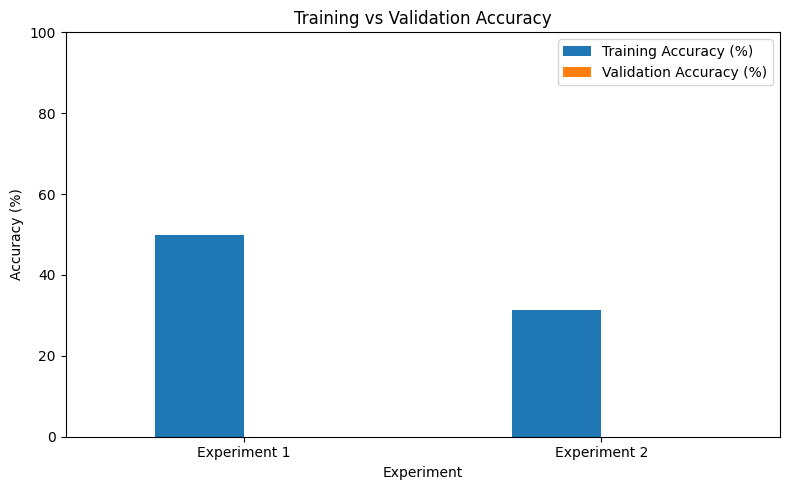

In [ ]:
import matplotlib.pyplot as plt

results.plot(
    x="Experiment",
    y=["Training Accuracy (%)", "Validation Accuracy (%)"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Training vs Validation Accuracy")
plt.ylabel("Accuracy (%)")
plt.xlabel("Experiment")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

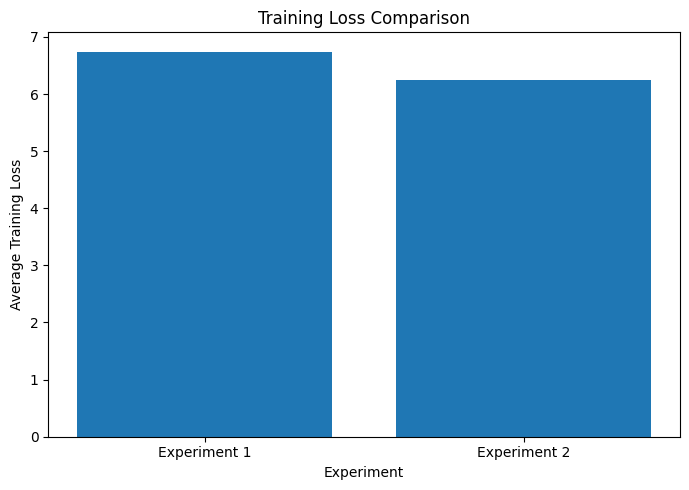

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    results["Experiment"],
    results["Training Loss"]
)

plt.title("Training Loss Comparison")
plt.ylabel("Average Training Loss")
plt.xlabel("Experiment")

plt.tight_layout()
plt.show()

In [ ]:
model_v2.save_pretrained("./experiment2_lora")
tokenizer.save_pretrained("./experiment2_lora")

print("Experiment 2 model saved successfully!")

Experiment 2 model saved successfully!
